# NHL: предсказать успешность команды в следующем сезоне

**Тестовое задание • 100 баллов**

Вы аналитик, которому после окончания сезона нужно оценить перспективы команды
на следующий год. Соберите таблицу с учебного сайта
[Scrape This Site - Hockey Teams](https://www.scrapethissite.com/pages/forms/),
изучите данные и постройте модель классификации.
В работе оцениваются корректность исследования и обоснованность решений.

Ориентир времени: 6-10 часов (знание хоккея не требуется).
Можно обращаться к документации и пользоваться вспомогательными инструментами.
Укажите, чем пользовались; отвечайте за правильность и понимание сданной работы.
Подтверждайте ответы результатами из своего ноутбука.

## Что сдавать

Выполненный IPynb с видимыми результатами и ответами и исходный `data/hockey_raw.csv` разместите на платформе githib.com.
Укажите имя, дату и использованные источники и инструменты в README.

## Что предсказывает модель

Одна строка признаков описывает команду в сезоне `t`.
`target=1`, если доля побед той же команды в сезоне `t+1` строго выше медианной
доли побед всех команд в сезоне `t+1`. В остальных случаях `target=0`.

Медиану считайте по полной исходной таблице будущего года до отбора пар.
В пары включайте одинаковые названия команды с разницей меток сезонов ровно в один год.
Строки без пары исключайте и учитывайте в описании данных.
Будущий `win_rate` и будущая медиана используются для построения target и анализа
готовых прогнозов. Признаки модели должны быть известны после сезона `t`.

## Схема проверки

Делите данные по году целевого сезона:

| Часть | target_year | Назначение |
|---|---|---|
| train | не позднее 2005 | Подготовка данных и обучение |
| validation | 2006-2008 | Сравнение вариантов и выбор решения |
| test | 2009-2011 | Одна итоговая оценка выбранного решения |

Основная метрика: ROC-AUC по вероятности класса 1.
На итоговом этапе также используйте F1 и accuracy при пороге 0.5.
Финальный test используйте после выбора решения на validation.

## Как оценивается работа

| Область | Баллы |
|---|---:|
| Сбор и понимание данных | 15 |
| Построение задачи и корректность проверки | 20 |
| Исследовательский анализ | 20 |
| Модели и эксперименты | 25 |
| Итоговая оценка и анализ ошибок | 15 |
| Ясность и воспроизводимость | 5 |
| **Всего** | **100** |

Ниже перечислены обязательные этапы работы. Внутри них вы самостоятельно выбираете
исследовательские вопросы, графики, признаки, обработку данных, эксперимент и способ
разбора ошибок. Оценивается качество решений, а не совпадение с эталонным маршрутом.
Сложность метода сама по себе не даёт преимущества. Корректный эксперимент может
получить полный балл и в случае отсутствия улучшения.

## Требования к сбору

Итоговая исходная таблица должна иметь столбцы `team`, `year`, `wins`, `losses`,
`ot_losses`, `win_rate`, `goals_for`, `goals_against`, `goal_diff`.
Самостоятельно исследуйте страницу и определите способ получения всей таблицы.

**Автор:** —  
**Дата:** 13 октября 2026 года.  
**Источники:** [таблица Scrape This Site](https://www.scrapethissite.com/pages/forms/),
[документация requests](https://requests.readthedocs.io/),
[Beautiful Soup](https://www.crummy.com/software/BeautifulSoup/bs4/doc/),
[pandas](https://pandas.pydata.org/docs/),
[scikit-learn](https://scikit-learn.org/stable/).  
**Инструменты:** Python, pandas, NumPy, requests, Beautiful Soup, matplotlib, scikit-learn,
Jupyter/IPython; Codex использован для подготовки кода, запуска и пояснений.

Код написан простыми шагами: обычный цикл при сборе, таблицы pandas,
два варианта одной логистической регрессии. Сложного подбора параметров нет.


In [1]:
%matplotlib inline
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score, confusion_matrix

pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)
plt.rcParams["figure.figsize"] = (8, 4)
Path("results").mkdir(exist_ok=True)

## Раздел 1. Сбор и понимание данных: 15 баллов

### 1.1. Соберите и сохраните данные

Соберите все страницы сайта в одну таблицу с указанными девятью столбцами.
Сохраните исходную выгрузку в `data/hockey_raw.csv`. Укажите URL и дату сбора,
число обработанных страниц и число строк. Покажите, как проверили,
что сбор не ограничился первой страницей и при повторном анализе можно читать CSV.

In [2]:
"""Сбор таблицы с учебного сайта. Запуск: python collect_data.py."""

import hashlib
import json
import time
from datetime import datetime
from pathlib import Path
from urllib.parse import parse_qs, urlparse
from zoneinfo import ZoneInfo

import pandas as pd
import requests
from bs4 import BeautifulSoup


def collect_hockey():
    url = "https://www.scrapethissite.com/pages/forms/"
    session = requests.Session()
    session.headers.update({"User-Agent": "Mozilla/5.0"})

    response = session.get(url, timeout=60)
    response.raise_for_status()
    first_page = BeautifulSoup(response.text, "html.parser")

    # Номера страниц берём из ссылок, а не задаём вручную.
    page_numbers = []
    for link in first_page.select(".pagination a"):
        query = parse_qs(urlparse(link["href"]).query)
        if "page_num" in query:
            page_numbers.append(int(query["page_num"][0]))
    if not page_numbers:
        raise ValueError("Не найдены ссылки на страницы")
    last_page = max(page_numbers)

    columns = ["team", "year", "wins", "losses", "ot_losses", "win_rate",
               "goals_for", "goals_against", "goal_diff"]
    rows = []
    pages = []

    for page in range(1, last_page + 1):
        if page == 1:
            soup = first_page
        else:
            time.sleep(0.3)
            response = session.get(url, params={"page_num": page}, timeout=60)
            response.raise_for_status()
            soup = BeautifulSoup(response.text, "html.parser")

        page_rows = []
        for tr in soup.select("tr.team"):
            values = [td.get_text(strip=True) for td in tr.select("td")]
            if len(values) != len(columns):
                raise ValueError(f"На странице {page} изменилась структура таблицы")
            page_rows.append(values)
        if not page_rows:
            raise ValueError(f"Страница {page} оказалась пустой")

        rows.extend(page_rows)
        pages.append({"page": page, "rows": len(page_rows),
                      "first_team": page_rows[0][0], "first_year": int(page_rows[0][1]),
                      "last_team": page_rows[-1][0], "last_year": int(page_rows[-1][1])})
        print(f"Страница {page}/{last_page}: {len(page_rows)} строк", flush=True)

    data = pd.DataFrame(rows, columns=columns)
    for column in columns[1:]:
        data[column] = pd.to_numeric(data[column].replace("", None), errors="raise")

    if data.duplicated(["team", "year"]).any():
        raise ValueError("Найдены повторяющиеся пары команда-год; выгрузка не сохранена")

    Path("data").mkdir(exist_ok=True)
    csv_path = Path("data/hockey_raw.csv")
    data.to_csv(csv_path, index=False)
    metadata = {
        "url": url,
        "collected_at": datetime.now(ZoneInfo("Europe/Moscow")).isoformat(),
        "pages_processed": last_page,
        "rows": len(data),
        "sha256": hashlib.sha256(csv_path.read_bytes()).hexdigest(),
        "pages": pages,
    }
    Path("data/collection_info.json").write_text(
        json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    return data


# При повторном запуске используем сохранённую выгрузку.
# Для нового сбора нужно поменять False на True.
COLLECT_AGAIN = False
if COLLECT_AGAIN or not Path("data/hockey_raw.csv").exists():
    collect_hockey()

raw = pd.read_csv("data/hockey_raw.csv")
info = json.loads(Path("data/collection_info.json").read_text())
page_log = pd.DataFrame(info["pages"])
assert len(raw) == info["rows"] == page_log["rows"].sum()
assert hashlib.sha256(Path("data/hockey_raw.csv").read_bytes()).hexdigest() == info["sha256"]
print("Источник:", info["url"])
print("Дата сбора:", info["collected_at"])
print("Страниц:", info["pages_processed"], "Строк:", len(raw))
print("Годы:", raw["year"].min(), "—", raw["year"].max())
display(page_log)
display(raw.head())

Источник: https://www.scrapethissite.com/pages/forms/
Дата сбора: 2026-10-13T15:38:08.102748+03:00
Страниц: 24 Строк: 582
Годы: 1990 — 2011


,page,rows,first_team,first_year,last_team,last_year
0,1,25,Boston Bruins,1990,Chicago Blackhawks,1991
1,2,25,Detroit Red Wings,1991,Hartford Whalers,1992
2,3,25,Los Angeles Kings,1992,Edmonton Oilers,1993
3,4,25,Florida Panthers,1993,Detroit Red Wings,1994
4,5,25,Edmonton Oilers,1994,Colorado Avalanche,1995
5,6,25,Dallas Stars,1995,Chicago Blackhawks,1996
6,7,25,Colorado Avalanche,1996,Calgary Flames,1997
7,8,25,Carolina Hurricanes,1997,Buffalo Sabres,1998
8,9,25,Calgary Flames,1998,Mighty Ducks of Anaheim,1999
9,10,25,Atlanta Thrashers,1999,Toronto Maple Leafs,1999


,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
0,Boston Bruins,1990,44,24,NaN,0.550,299,264,35
1,Buffalo Sabres,1990,31,30,NaN,0.388,292,278,14
2,Calgary Flames,1990,46,26,NaN,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,NaN,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,NaN,0.425,273,298,-25


**Ответ 1.1:**

На странице строки команд имеют класс `team`, а ссылки под таблицей содержат `page_num`.
По ссылкам определил последний номер страницы, затем прошёл все номера обычным циклом.
Взял все девять ячеек каждой строки. Пустые значения сохранил как пропуски.

Источник: [Scrape This Site](https://www.scrapethissite.com/pages/forms/).
Дата, число страниц и строк выведены выше. В журнале видны и первая, и последняя страницы,
поэтому сбор не ограничен первой страницей. Уникальность команда-год проверяется ещё при сборе.
CSV читается через `pd.read_csv`; число строк и контрольная сумма сверяются с журналом.
Сам сбор можно повторить, установив `COLLECT_AGAIN = True`.

### 1.2. Проверьте качество таблицы

Изучите типы, пропуски и уникальность пары команда-год.
Добавьте не менее двух проверок согласованности, которые считаете важными
для последующего анализа. Покажите найденные особенности и обоснуйте
решения по их обработке. Сами проверки и способ представления результата выберите самостоятельно.

In [3]:
quality = pd.DataFrame({"type": raw.dtypes.astype(str), "missing": raw.isna().sum()})
display(quality)

count_columns = ["wins", "losses", "ot_losses", "goals_for", "goals_against"]
checks = pd.Series({
    "Дубликаты команда-год": int(raw.duplicated(["team", "year"]).sum()),
    "Неверная разность голов": int((raw["goal_diff"] != raw["goals_for"] - raw["goals_against"]).sum()),
    "Доля побед вне [0, 1]": int((~raw["win_rate"].between(0, 1)).sum()),
    "Отрицательные счётчики": int((raw[count_columns] < 0).sum().sum()),
    "Нецелые счётчики": int((raw[count_columns].drop(columns="ot_losses") % 1 != 0).sum().sum()),
    "Нецелые известные OT-поражения": int((raw["ot_losses"].dropna() % 1 != 0).sum()),
})
display(checks)
assert (checks == 0).all()
assert raw.drop(columns="ot_losses").notna().all().all()
assert raw["team"].str.strip().ne("").all()

by_year = raw.groupby("year").agg(
    teams=("team", "size"),
    missing_ot=("ot_losses", lambda values: values.isna().sum()),
    median_win_rate=("win_rate", "median"),
)
display(by_year)
missing_years = sorted(set(range(raw["year"].min(), raw["year"].max() + 1)) - set(raw["year"]))
print("Пропущенные годы:", missing_years)

,type,missing
team,str,0
year,int64,0
wins,int64,0
losses,int64,0
ot_losses,float64,224
win_rate,float64,0
goals_for,int64,0
goals_against,int64,0
goal_diff,int64,0


Дубликаты команда-год             0
Неверная разность голов           0
Доля побед вне [0, 1]             0
Отрицательные счётчики            0
Нецелые счётчики                  0
Нецелые известные OT-поражения    0
dtype: int64

,teams,missing_ot,median_win_rate
year,,,
1990,21,21,0.4250
1991,22,22,0.4440
1992,24,24,0.4760
1993,26,26,0.4640
1994,26,26,0.4275
1995,26,26,0.4330
1996,26,26,0.4270
1997,26,26,0.4270
1998,27,27,0.4150


Пропущенные годы: [2004]


**Ответ 1.2:**

В таблице **582 строки и 9 столбцов**, дубликатов команда-год нет.
Пропуски есть только в `ot_losses`: **224**, все относятся к 1990–1998 годам.
В диапазоне 1990–2011 отсутствует **2004 год**. Его не восстанавливаю и не соединяю через него сезоны.

Проверил разность голов, диапазон доли побед, неотрицательность и целочисленность счётчиков:
во всех проверках число нарушений равно нулю. Типы и пропуски показаны в таблице выше.

Пустой `ot_losses` не стал заменять нулём: отсутствие значения само по себе не доказывает,
что поражений не было. В модель этот столбец не включаю. Исходный CSV оставляю без заполнения.
Не считаю долю побед как `wins / (wins + losses + ot_losses)`: в таблице нет отдельного
столбца ничьих, поэтому такой знаменатель может быть неполным. Беру готовый `win_rate` сайта.
Название команды сохраняю как на сайте: переименованные команды по условию не объединяю.

## Раздел 2. Построение задачи и корректность проверки: 20 баллов

### 2.1. Постройте target

Соедините строку команды в сезоне `t` с той же командой ровно в сезоне `t+1`
и постройте target по определению задания. Покажите число полученных пар,
число и годы исключённых строк, а также число случаев равенства будущей медиане.
Проверьте расчёт вручную минимум на двух содержательно разных примерах.

In [4]:
# Медиана считается по всем командам года, ещё до отбора пар.
medians = raw.groupby("year")["win_rate"].median()
future = raw[["team", "year", "win_rate"]].rename(columns={
    "year": "target_year", "win_rate": "future_win_rate"
})
future["future_median"] = future["target_year"].map(medians)

current = raw.copy()
current["target_year"] = current["year"] + 1
joined = current.merge(future, on=["team", "target_year"], how="left", validate="one_to_one")
excluded = joined[joined["future_win_rate"].isna()].copy()
excluded["reason"] = "Нет той же команды в следующем году"
excluded.loc[~excluded["target_year"].isin(raw["year"]), "reason"] = "Следующего года нет в таблице"
print("Исключено строк:", len(excluded))
display(excluded.groupby(["year", "reason"]).size().rename("rows").reset_index())

pairs = joined.dropna(subset=["future_win_rate"]).copy()
pairs["target"] = (pairs["future_win_rate"] > pairs["future_median"]).astype(int)
assert (pairs["target_year"] == pairs["year"] + 1).all()
assert not pairs.duplicated(["team", "year"]).any()
assert np.allclose(pairs["future_median"], pairs["target_year"].map(medians))
ties = pairs[pairs["future_win_rate"] == pairs["future_median"]]
assert (ties["target"] == 0).all()
print("Пар:", len(pairs), "Равенств медиане:", len(ties))

# Три ручных примера: выше, ровно и ниже медианы.
examples = pd.concat([
    pairs[pairs["target"] == 1].head(1),
    ties.head(1),
    pairs[pairs["future_win_rate"] < pairs["future_median"]].head(1),
])
display(examples[["team", "year", "target_year", "win_rate", "future_win_rate", "future_median", "target"]])
for _, row in examples.iterrows():
    values = sorted(raw.loc[raw["year"] == row["target_year"], "win_rate"].tolist())
    middle = len(values) // 2
    if len(values) % 2 == 1:
        manual_median = values[middle]
    else:
        manual_median = (values[middle - 1] + values[middle]) / 2
    manual_target = int(row["future_win_rate"] > manual_median)
    assert manual_target == row["target"]
    print(f'{row["team"]}, {row["year"]} → {row["target_year"]}: '
          f'{row["future_win_rate"]} > {manual_median}? target = {manual_target}; '
          f'медиана из всех {len(values)} команд года')

# История команды: только ровно предыдущий год, без заполнения через разрывы.
previous = raw[["team", "year", "win_rate"]].rename(columns={"win_rate": "previous_win_rate"})
previous["year"] = previous["year"] + 1
pairs = pairs.merge(previous, on=["team", "year"], how="left", validate="one_to_one")
excluded.to_csv("results/excluded_rows.csv", index=False)

Исключено строк: 66


,year,reason,rows
0,1992,Нет той же команды в следующем году,1
1,1994,Нет той же команды в следующем году,1
2,1995,Нет той же команды в следующем году,1
3,1996,Нет той же команды в следующем году,1
4,2003,Следующего года нет в таблице,30
5,2005,Нет той же команды в следующем году,1
6,2010,Нет той же команды в следующем году,1
7,2011,Следующего года нет в таблице,30


Пар: 516 Равенств медиане: 23


,team,year,target_year,win_rate,future_win_rate,future_median,target
0,Boston Bruins,1990,1991,0.550,0.450,0.444,1
31,New Jersey Devils,1991,1992,0.475,0.476,0.476,0
1,Buffalo Sabres,1990,1991,0.388,0.388,0.444,0


Boston Bruins, 1990 → 1991: 0.45 > 0.444? target = 1; медиана из всех 22 команд года
New Jersey Devils, 1991 → 1992: 0.476 > 0.476? target = 0; медиана из всех 24 команд года
Buffalo Sabres, 1990 → 1991: 0.388 > 0.444? target = 0; медиана из всех 22 команд года


**Ответ 2.1:**

Получилось **516 пар**, исключено **66 исходных строк**, равенств будущей медиане — **23**.
По 30 строк исключены за 2003 и 2011 годы: следующего года нет в выгрузке.
Ещё по одной строке исключены за 1992, 1994, 1995, 1996, 2005 и 2010 годы:
в следующем году нет команды с тем же названием.

Объединение сделано по одинаковому названию команды и `target_year = year + 1`.
Медиана взята из полной исходной таблицы будущего года, а не только из команд с парой.
В журнале выше видно число исключений по каждому году и причину.

В трёх примерах вручную отсортировал все значения будущего года и выбрал середину
(для чётного количества — среднее двух центральных значений). Затем сравнил с долей побед.
Результаты выше показывают три случая: строго выше — 1, равенство — 0, ниже — 0.
Использую значения сайта, округлённые до трёх знаков: сравнение не восстанавливает
неизвестные точные доли побед.

### 2.2. Подготовьте временную проверку

Разделите пары на train, validation и test по заданным границам target_year.
Покажите для каждой части фактические годы, размер и долю класса 1.
Назовите минимум два столбца, которые появились при построении target,
но недоступны модели в момент прогноза. Объясните, почему случайное перемешивание
строк отвечало бы на другой вопрос, чем выбранная временная схема.

In [5]:
train = pairs[pairs["target_year"] <= 2005].copy()
validation = pairs[pairs["target_year"].between(2006, 2008)].copy()
test = pairs[pairs["target_year"].between(2009, 2011)].copy()

parts = {"train": train, "validation": validation, "test": test}
split_rows = []
for name, part in parts.items():
    split_rows.append({"part": name, "target_years": sorted(part["target_year"].unique().tolist()),
                       "rows": len(part), "class_1_share": part["target"].mean()})
    assert part["target"].nunique() == 2
split_table = pd.DataFrame(split_rows)
display(split_table)
assert len(train) + len(validation) + len(test) == len(pairs)
assert train["target_year"].max() < validation["target_year"].min()
assert validation["target_year"].max() < test["target_year"].min()

,part,target_years,rows,class_1_share
0,train,"[1991, 1992, 1993, 1994, 1995, 1996, 1997, 199...",338,0.4911
1,validation,"[2006, 2007, 2008]",89,0.4719
2,test,"[2009, 2010, 2011]",89,0.4719


**Ответ 2.2:**

| Часть | Фактические target_year | Строки | Доля класса 1 |
|---|---|---:|---:|
| train | 1991–2003 | 338 | 0,4911 |
| validation | 2006–2008 | 89 | 0,4719 |
| test | 2009–2011 | 89 | 0,4719 |

Граница train остаётся «не позднее 2005», но пар с целевыми 2004 и 2005 годами нет:
для них отсутствует один из двух соседних сезонов.

`future_win_rate` и `future_median` нельзя передавать модели: после сезона `t` их ещё нет.
Также нельзя передавать `target`. Для обучения использую только явный список признаков,
а не все столбцы таблицы. `target_year` нужен для разделения и в модель не входит.

`previous_win_rate` относится к сезону `t-1`. Для сезона 2005 история 2003 не подставляется:
не хватает ровно предыдущего года. Такой пропуск позже заполняется внутри Pipeline по train.

При случайном перемешивании будущие сезоны могли бы попасть в обучение, а старые — в проверку.
Это проверяло бы восстановление случайно скрытых строк общей истории. Здесь проверяем
другой вопрос: умеет ли модель, обученная на прошлом, предсказывать более поздние сезоны.

## Раздел 3. Исследовательский анализ: 20 баллов

### 3.1. Сформулируйте вопросы к данным

До построения основных графиков сформулируйте не менее двух собственных
исследовательских вопросов, связанных с будущей успешностью команд
или устройством данных. Для каждого запишите ожидаемый результат и объясните,
как ответ может повлиять на выбор признаков, обработку или интерпретацию модели.

In [6]:
# Гипотезы записаны ниже до графиков. Для анализа используем только train.
print("EDA: только train, целевые сезоны до 2005 включительно")

EDA: только train, целевые сезоны до 2005 включительно


**Ответ 3.1 — вопросы до построения графиков:**

1. Связана ли высокая доля побед сейчас с успешностью в следующем году?
Ожидаю положительную связь, но не идеальную: команды могут становиться сильнее или слабее.
Если связь есть, `win_rate` будет основным признаком и простым ориентиром.
Проверю долю будущих успешных команд в четырёх группах текущего `win_rate`
и корреляцию текущей и будущей доли побед.
2. Даёт ли предыдущий сезон дополнительную информацию при похожей текущей доле побед?
Ожидаю, что команда с хорошим предыдущим сезоном чаще остаётся сильной.
Если это видно, проверю добавление `previous_win_rate` в эксперименте.
Разделю текущую долю побед на три группы, а историю внутри каждой — на ниже и не ниже
медианы прошлого года. Покажу и доли успеха, и размеры групп.

Графики и выводы строю по train, чтобы test не влиял на выбор модели.

### 3.2. Проведите исследовательский анализ

Ответьте на вопросы из пункта 3.1 с помощью числовых сводок и визуализаций.
Количество и типы графиков выберите сами: их должно быть достаточно,
чтобы подтвердить выводы, а каждый график должен отвечать на сформулированный вопрос.
Покажите хотя бы одно конкретное наблюдение на уровне команды или сезона.
Для каждого вывода укажите ограничение интерпретации.

,rows,success_share,mean_current,mean_future
current_group,,,,
"(0.118, 0.366]",90,0.2111,0.3049,0.3690
"(0.366, 0.439]",86,0.3605,0.4101,0.4239
"(0.439, 0.512]",89,0.5955,0.4794,0.4625
"(0.512, 0.756]",73,0.8630,0.5709,0.5129


Корреляция текущего и будущего win_rate: 0.5615


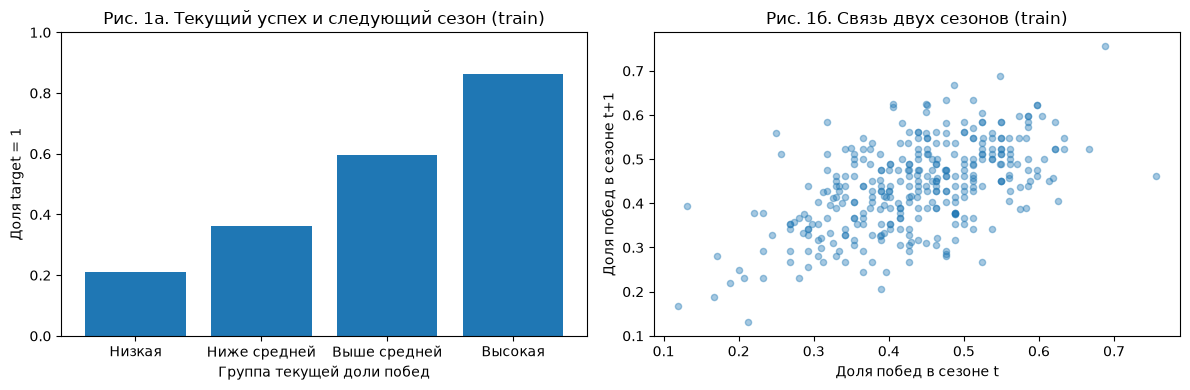

rows  success_share
current_group  previous_group                      
(0.13, 0.4]    Не ниже медианы    23         0.3913
               Ниже медианы       80         0.2125
(0.4, 0.488]   Не ниже медианы    65         0.5538
               Ниже медианы       45         0.3778
(0.488, 0.756] Не ниже медианы    71         0.8732
               Ниже медианы       20         0.6500

Строк train без предыдущего сезона: 34


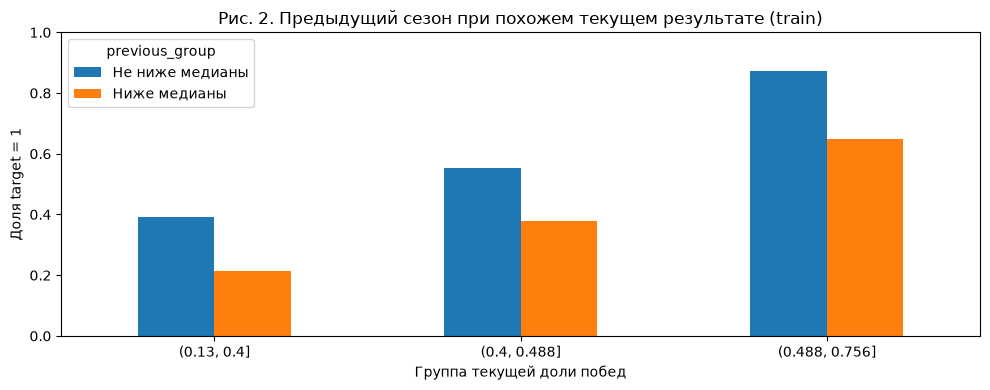

,team,year,previous_win_rate,win_rate,future_win_rate,future_median,target
0,Boston Bruins,1990,NaN,0.550,0.450,0.4440,1
21,Boston Bruins,1991,0.550,0.450,0.607,0.4760,1
43,Boston Bruins,1992,0.450,0.607,0.500,0.4640,1
67,Boston Bruins,1993,0.607,0.500,0.562,0.4275,1
93,Boston Bruins,1994,0.500,0.562,0.488,0.4330,1
118,Boston Bruins,1995,0.562,0.488,0.317,0.4270,0


In [7]:
eda = train.copy()
eda["current_group"] = pd.qcut(eda["win_rate"], q=4, duplicates="drop")
current_table = eda.groupby("current_group", observed=True).agg(
    rows=("target", "size"), success_share=("target", "mean"),
    mean_current=("win_rate", "mean"), mean_future=("future_win_rate", "mean"),
)
display(current_table)
correlation = eda["win_rate"].corr(eda["future_win_rate"])
print("Корреляция текущего и будущего win_rate:", round(correlation, 4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(len(current_table)), current_table["success_share"])
axes[0].set_xticks(range(len(current_table)), ["Низкая", "Ниже средней", "Выше средней", "Высокая"])
axes[0].set_ylim(0, 1)
axes[0].set_xlabel("Группа текущей доли побед")
axes[0].set_ylabel("Доля target = 1")
axes[0].set_title("Рис. 1а. Текущий успех и следующий сезон (train)")
axes[1].scatter(eda["win_rate"], eda["future_win_rate"], alpha=0.4, s=20)
axes[1].set_xlabel("Доля побед в сезоне t")
axes[1].set_ylabel("Доля побед в сезоне t+1")
axes[1].set_title("Рис. 1б. Связь двух сезонов (train)")
fig.tight_layout()
fig.savefig("results/current_win_rate.png", dpi=150)
plt.show()

history = train.dropna(subset=["previous_win_rate"]).copy()
history["current_group"] = pd.qcut(history["win_rate"], q=3, duplicates="drop")
history["previous_median"] = (history["year"] - 1).map(medians)
history["previous_group"] = np.where(history["previous_win_rate"] >= history["previous_median"],
                                     "Не ниже медианы", "Ниже медианы")
history_table = history.groupby(["current_group", "previous_group"], observed=True).agg(
    rows=("target", "size"), success_share=("target", "mean")
)
display(history_table)
print("Строк train без предыдущего сезона:", train["previous_win_rate"].isna().sum())

history_table["success_share"].unstack().plot(kind="bar", ylim=(0, 1), rot=0, figsize=(10, 4))
plt.title("Рис. 2. Предыдущий сезон при похожем текущем результате (train)")
plt.xlabel("Группа текущей доли побед")
plt.ylabel("Доля target = 1")
plt.tight_layout()
plt.savefig("results/previous_win_rate.png", dpi=150)
plt.show()

team_example = train[train["team"] == "Boston Bruins"]
display(team_example[["team", "year", "previous_win_rate", "win_rate", "future_win_rate", "future_median", "target"]].head(6))

**Ответ 3.2:**

Вопрос 1: доля будущего успеха растёт по четырём группам текущего `win_rate`:
**21,1%, 36,0%, 59,6%, 86,3%** (90, 86, 89 и 73 строки).
Корреляция текущей и будущей доли побед — **0,5615**. Это поддерживает выбор `win_rate`.

Вопрос 2: внутри всех трёх групп текущего результата у команд с прошлым сезоном не ниже
медианы доля будущего успеха выше. Например, в средней группе: **55,4% (65 строк)**
против **37,8% (45 строк)**. Поэтому прошлый сезон проверяю как дополнительный признак.

Конкретный пример из таблицы: Boston Bruins в 1995 году имели `win_rate = 0,488`,
но в 1996 году — только `0,317`, ниже медианы `0,427`, поэтому target равен 0.
Хороший текущий результат не гарантирует успешный следующий сезон.
Одна команда не описывает всю лигу; этот пример показывает возможное изменение, а не его причину.

На рис. 1 видна связь текущего и будущего результата, но есть большой разброс.
Ограничение: связь не доказывает причинность, и повторные наблюдения одних команд зависимы.
Групповые доли успеха не являются вероятностями для конкретной команды.

Рис. 2 сравнивает историю при похожем текущем результате. Ограничение: внутри широких
групп текущие доли побед всё равно различаются, а размеры подгрупп невелики.
Это повод проверить признак на validation, а не доказательство его пользы.
Строки без истории в этот график не вошли, но из обучения они не исключаются.

## Раздел 4. Модели и эксперименты: 25 баллов

### 4.1. Постройте ориентиры

На train обучите простой константный baseline и оцените его на validation.
Отдельно используйте текущий `win_rate` как простую оценку для ранжирования
будущего класса. Посчитайте ROC-AUC обоих ориентиров и объясните,
какую планку задаёт каждый из них для обучаемой модели.

In [8]:
dummy = DummyClassifier(strategy="prior")
dummy.fit(train[["win_rate"]], train["target"])
constant_validation = dummy.predict_proba(validation[["win_rate"]])[:, 1]
current_validation = validation["win_rate"].to_numpy()

baseline_table = pd.DataFrame({
    "model": ["Константа", "Текущий win_rate"],
    "validation_roc_auc": [
        roc_auc_score(validation["target"], constant_validation),
        roc_auc_score(validation["target"], current_validation),
    ],
})
display(baseline_table)
print("Постоянная вероятность по train:", round(train["target"].mean(), 4))

,model,validation_roc_auc
0,Константа,0.5000
1,Текущий win_rate,0.7568


Постоянная вероятность по train: 0.4911


**Ответ 4.1:**

ROC-AUC на validation: **константа — 0,5000**, **текущий win_rate — 0,7568**.
Постоянная вероятность из train — **0,4911**.

Константа всем даёт одну вероятность — долю класса 1 в train. Она никого не ранжирует,
поэтому ROC-AUC равен 0.5. Это минимальный ориентир.

Текущий `win_rate` ранжирует команды по уже известному результату. Это более сильный
ориентир: обучаемая модель должна быть полезнее простого переноса текущего успеха.
Сам текущий `win_rate` не является обученной вероятностью будущего класса.

### 4.2. Постройте первую модель

Обучите логистическую регрессию. Самостоятельно выберите признаки и обоснуйте выбор.
Обработку пропусков и масштабирование включите в Pipeline и обучайте только на train.
Посчитайте ROC-AUC на validation и сравните с обоими ориентирами.
Объясните результат без использования test.

In [9]:
features = ["win_rate", "goal_diff"]

def make_model():
    return Pipeline([
        ("fill_missing", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000, random_state=42)),
    ])

model = make_model()
model.fit(train[features], train["target"])
validation_probability = model.predict_proba(validation[features])[:, 1]
first_auc = roc_auc_score(validation["target"], validation_probability)
print("Признаки:", features)
print("ROC-AUC первой модели на validation:", round(first_auc, 4))
display(pd.concat([baseline_table, pd.DataFrame({
    "model": ["Логистическая регрессия"], "validation_roc_auc": [first_auc]
})], ignore_index=True))

Признаки: ['win_rate', 'goal_diff']
ROC-AUC первой модели на validation: 0.772


,model,validation_roc_auc
0,Константа,0.5000
1,Текущий win_rate,0.7568
2,Логистическая регрессия,0.7720


**Ответ 4.2:**

ROC-AUC первой регрессии на validation — **0,7720**.
Это выше константы и на **0,0152** выше ориентира по текущей доле побед.
Разность голов может дополнить информацию о силе команды, однако небольшая разница
на 89 строках ещё не доказывает устойчивого преимущества.

Выбрал два признака: `win_rate` показывает текущую долю побед, а `goal_diff` — разницу
забитых и пропущенных голов. Оба известны после текущего сезона.
Саму разность и оба её слагаемых одновременно не включаю, чтобы не дублировать информацию.
Имя команды не кодирую: выборка небольшая, новые названия не имеют обученной истории.
Год тоже не включаю, чтобы модель не делала ставку на продолжение линейного тренда времени.

Медианы для заполнения и параметры StandardScaler вычисляются только при `fit` на train.
У двух исходных признаков пропусков нет, но Pipeline нужен и для следующего эксперимента.
Результат сравниваю только по validation; по нему ещё нельзя судить о более позднем test.

### 4.3. Проведите собственный эксперимент

Выберите одно осмысленное изменение: состав признаков, способ обработки данных,
параметры или другой алгоритм. До запуска запишите ожидаемый эффект и его причину.
Изменяйте одну понятную часть решения, сравните варианты на validation
и зафиксируйте выбор финальной модели до просмотра test.
Дополнительные эксперименты допустимы, но их количество само по себе не оценивается.

**Ожидание до эксперимента:** добавлю только `previous_win_rate`.
Два сезона могут лучше описать устойчивую силу команды, чем один: хороший результат
в обоих сезонах менее похож на случайный скачок. Ожидаю небольшое улучшение ROC-AUC.
Проверю это на validation; при отсутствии улучшения оставлю исходную модель.

In [10]:
# Меняем только состав признаков: добавляем результат ровно предыдущего года.
experiment_features = features + ["previous_win_rate"]
experiment_model = make_model()
experiment_model.fit(train[experiment_features], train["target"])
experiment_probability = experiment_model.predict_proba(validation[experiment_features])[:, 1]
experiment_auc = roc_auc_score(validation["target"], experiment_probability)

experiments = pd.DataFrame({
    "model": ["Логистическая регрессия", "Регрессия с предыдущим сезоном"],
    "validation_roc_auc": [first_auc, experiment_auc],
})
display(experiments)

# Правило выбора: больше ROC-AUC на validation. При равенстве — простая модель.
if experiment_auc > first_auc:
    final_model = experiment_model
    final_features = experiment_features
    final_name = "Регрессия с предыдущим сезоном"
    final_validation_auc = experiment_auc
else:
    final_model = model
    final_features = features
    final_name = "Логистическая регрессия"
    final_validation_auc = first_auc

choice = {
    "model": final_name, "features": final_features,
    "C": 1.0, "solver": "lbfgs", "max_iter": 1000, "random_state": 42,
    "imputer": "median (train only)", "scaler": "StandardScaler (train only)",
    "threshold": 0.5, "validation_roc_auc": final_validation_auc,
    "selection_rule": "Наибольший validation ROC-AUC; при равенстве исходная модель",
    "fit_data": "train only; no refit after selection",
}
Path("results/model_choice.json").write_text(json.dumps(choice, ensure_ascii=False, indent=2))
print("Выбор зафиксирован до оценки test:")
print(json.dumps(choice, ensure_ascii=False, indent=2))
experiments.to_csv("results/validation_models.csv", index=False)

,model,validation_roc_auc
0,Логистическая регрессия,0.772
1,Регрессия с предыдущим сезоном,0.728


Выбор зафиксирован до оценки test:
{
  "model": "Логистическая регрессия",
  "features": [
    "win_rate",
    "goal_diff"
  ],
  "C": 1.0,
  "solver": "lbfgs",
  "max_iter": 1000,
  "random_state": 42,
  "imputer": "median (train only)",
  "scaler": "StandardScaler (train only)",
  "threshold": 0.5,
  "validation_roc_auc": 0.7720364741641338,
  "selection_rule": "Наибольший validation ROC-AUC; при равенстве исходная модель",
  "fit_data": "train only; no refit after selection"
}


**Ответ 4.3:**

Ожидаемое улучшение не подтвердилось: исходная модель — **0,7720**,
вариант с `previous_win_rate` — **0,7280**. Снижение составило **0,0441**.
Выбрал исходную модель с признаками **`win_rate`, `goal_diff`**.

Наблюдение на train не перенеслось на validation. Возможные объяснения —
дублирование текущего результата историей, зависимость от периода и заполнение
отсутствующей истории. Это гипотезы; одним сравнением их нельзя разделить.

Все остальные настройки одинаковы: заполнение медианой train, масштабирование,
логистическая регрессия с `C=1.0`. История берётся из исходных прошлых сезонов,
даже если эти строки не вошли в пары для обучения. Это доступная в момент прогноза информация.
Если истории нет, Pipeline подставляет медиану этого признака из train.

Выбор сохранён в `results/model_choice.json` до следующей ячейки с оценкой test.
Модель дальше не переобучаю и не меняю: validation использую только для выбора варианта.

## Раздел 5. Итоговая оценка и анализ ошибок: 15 баллов

### 5.1. Проведите итоговую оценку

Зафиксируйте выбранную модель, признаки и параметры, затем один раз оцените её на test.
Покажите ROC-AUC, F1 и accuracy при пороге 0.5 для выбранной модели
и сопоставимых baseline. Объясните различия между метриками и сравните
результаты validation и test. После этого не меняйте выбранное решение.

In [11]:
# Первое использование test для оценки выбранного решения.
# Все модели уже обучены, признаки и порог уже зафиксированы.
test_probability = final_model.predict_proba(test[final_features])[:, 1]
constant_test = dummy.predict_proba(test[["win_rate"]])[:, 1]
current_test = test["win_rate"].to_numpy()

def metrics_row(name, probability):
    prediction = (probability >= 0.5).astype(int)
    return {"model": name, "ROC_AUC": roc_auc_score(test["target"], probability),
            "F1": f1_score(test["target"], prediction, zero_division=0),
            "accuracy": accuracy_score(test["target"], prediction)}

test_metrics = pd.DataFrame([
    metrics_row("Константа", constant_test),
    metrics_row("Текущий win_rate", current_test),
    metrics_row(final_name, test_probability),
])
display(test_metrics)
print("ROC-AUC выбранной модели: validation =", round(final_validation_auc, 4),
      "test =", round(test_metrics.iloc[2]["ROC_AUC"], 4))
print("Матрица ошибок: строки — факт 0/1, столбцы — прогноз 0/1")
display(pd.DataFrame(confusion_matrix(test["target"], test_probability >= 0.5, labels=[0, 1]),
                     index=["Факт 0", "Факт 1"], columns=["Прогноз 0", "Прогноз 1"]))

test_results = test.copy()
test_results["probability"] = test_probability
test_results["prediction"] = (test_probability >= 0.5).astype(int)
test_results["correct"] = test_results["prediction"] == test_results["target"]
test_results.to_csv("results/test_predictions.csv", index=False)
test_metrics.to_csv("results/test_metrics.csv", index=False)

,model,ROC_AUC,F1,accuracy
0,Константа,0.5000,0.0000,0.5281
1,Текущий win_rate,0.7404,0.6522,0.6404
2,Логистическая регрессия,0.7596,0.7059,0.6629


ROC-AUC выбранной модели: validation = 0.772 test = 0.7596
Матрица ошибок: строки — факт 0/1, столбцы — прогноз 0/1


,Прогноз 0,Прогноз 1
Факт 0,23,24
Факт 1,6,36


**Ответ 5.1:**

| Вариант | ROC-AUC | F1 | accuracy |
|---|---:|---:|---:|
| Константа | 0,5000 | 0,0000 | 0,5281 |
| Текущий win_rate | 0,7404 | 0,6522 | 0,6404 |
| Выбранная регрессия | **0,7596** | **0,7059** | **0,6629** |

У выбранной модели ROC-AUC снизился с **0,7720 на validation** до **0,7596 на test**
(на 0,0124). Она выше текущего `win_rate` по всем трём итоговым метрикам
в этой конкретной проверке. Верно классифицированы **59 из 89 строк**, ошибок — **30**.

ROC-AUC оценивает порядок команд по оценке вероятности и не зависит от порога 0.5.
Accuracy — доля верных ответов при этом пороге. F1 объединяет точность и полноту
именно для класса 1. Поэтому хорошие ранжирование и классификация не обязаны совпадать.

Для всех вариантов применил одинаковый порог 0.5. У текущего `win_rate` это только
условное правило: его оценка не откалибрована под вероятность следующего успеха.
Константа по train ниже 0.5, поэтому предсказывает только 0: F1 равен нулю,
хотя accuracy ненулевой. Матрица ошибок выбранной модели приведена выше.

Test содержит всего три года и небольшое число команд. Разница с validation
может зависеть от состава сезонов, поэтому не считаю её доказательством стабильного улучшения.
После этой оценки модель, признаки и порог не менялись.

### 5.2. Разберите ошибки

Выберите от трёх до пяти ошибок финальной модели по явно указанному принципу.
Это могут быть наиболее уверенные ошибки, отдельный тип ошибки или другой
обоснованный набор. Покажите идентификаторы строк, вероятности и значения,
необходимые для анализа. Найдите общие черты и различия; отделите факты
из таблицы от гипотез и назовите данные, нужные для проверки одной гипотезы.

In [12]:
# Принцип отбора: пять самых уверенных неверных ответов.
errors = test_results[~test_results["correct"]].copy()
errors["confidence"] = np.where(errors["prediction"] == 1,
                                errors["probability"], 1 - errors["probability"])
errors["error_type"] = np.where(errors["prediction"] == 1, "Ложный успех", "Пропущенный успех")
errors["future_gap"] = errors["future_win_rate"] - errors["future_median"]
top_errors = errors.sort_values(["confidence", "team", "year"], ascending=[False, True, True]).head(5)
error_columns = ["team", "year", "target_year", "win_rate", "goal_diff", "previous_win_rate",
                 "probability", "prediction", "target", "future_win_rate", "future_median",
                 "future_gap", "confidence", "error_type"]
display(top_errors[error_columns])
print("Всего ошибок:", len(errors), "из", len(test_results))
display(errors.groupby("error_type").size().rename("rows"))
print("Среди пяти разобранных ошибок:")
display(top_errors.groupby("error_type").size().rename("rows"))
top_errors[error_columns].to_csv("results/top_errors.csv", index=False)

,team,year,target_year,win_rate,goal_diff,previous_win_rate,probability,prediction,target,future_win_rate,future_median,future_gap,confidence,error_type
429,Boston Bruins,2008,2009,0.646,78,0.500,0.9092,1,0,0.476,0.488,-0.012,0.9092,Ложный успех
479,Phoenix Coyotes,2009,2010,0.610,23,0.439,0.8080,1,0,0.524,0.524,0.000,0.8080,Ложный успех
474,New Jersey Devils,2009,2010,0.585,31,0.622,0.7933,1,0,0.463,0.524,-0.061,0.7933,Ложный успех
499,Los Angeles Kings,2010,2011,0.561,21,0.561,0.7430,1,0,0.488,0.500,-0.012,0.7430,Ложный успех
460,Buffalo Sabres,2009,2010,0.549,28,0.500,0.7412,1,0,0.524,0.524,0.000,0.7412,Ложный успех


Всего ошибок: 30 из 89


error_type
Ложный успех         24
Пропущенный успех     6
Name: rows, dtype: int64

Среди пяти разобранных ошибок:


error_type
Ложный успех    5
Name: rows, dtype: int64

**Ответ 5.2:**

Все пять наиболее уверенных ошибок — **ложный успех**. У этих команд текущая
доля побед 0,549–0,646 и положительная разность голов от +21 до +78,
но в следующем сезоне ни одна не оказалась строго выше медианы.

- **Boston Bruins, 2008 → 2009:** вероятность 0,9092; доля побед снизилась с 0,646
до 0,476 при будущей медиане 0,488. Самая уверенная ошибка.
- **Phoenix Coyotes, 2009 → 2010:** вероятность 0,8080; следующий результат 0,524
точно равен медиане 0,524. По строгому правилу это класс 0.
- **New Jersey Devils, 2009 → 2010:** вероятность 0,7933; будущая доля побед 0,463,
на 0,061 ниже медианы 0,524. Здесь падение сильнее, чем у ошибок рядом с границей.
- **Los Angeles Kings, 2010 → 2011:** вероятность 0,7430; будущий результат 0,488,
на 0,012 ниже медианы 0,500.
- **Buffalo Sabres, 2009 → 2010:** вероятность 0,7412; следующий результат 0,524
снова точно равен медиане.

Общее — модель переносит высокий текущий успех в будущее. Различие — у двух команд
ошибка вызвана попаданием точно на границу, у других результат оказался ниже неё.
Эти пять примеров выбраны специально
по уверенности и не описывают распределение всех 30 ошибок.

Выбрал пять ошибок с наибольшей уверенностью в неверном классе. Идентификатор строки —
название команды и текущий год, дополнительно показан год прогноза.
`future_gap` показывает, насколько будущий результат выше или ниже медианы.
Будущие значения здесь служат только для разбора уже готовых прогнозов.

Факты: исходные результаты и история в таблице, вероятность модели, направление ошибки,
будущий результат относительно медианы. Гипотеза: неожиданное изменение может быть
связано с травмами, составом или тренером. По этой таблице причину установить нельзя.
Для проверки гипотезы о травмах понадобятся даты травм ведущих игроков, пропущенные ими
матчи и состав команды за оба сезона. Данных об этом на сайте нет.

## Раздел 6. Выводы и воспроизводимость: 5 баллов

### 6.1. Сформулируйте выводы

Сформулируйте основные выводы и ограничения работы со ссылками на свои графики,
строки и метрики. Опишите минимум два решения, которые вы изменили
или подтвердили после получения результатов. Назовите одно улучшение,
которое вы сознательно не стали выполнять, и объясните причину.
Убедитесь, что последовательность работы и финальные параметры можно воспроизвести.

In [13]:
# Сохраняем короткий итог и числа для воспроизводимости.
summary = {
    "rows": len(raw), "pages": info["pages_processed"], "missing_ot": int(raw["ot_losses"].isna().sum()),
    "missing_years": missing_years, "pairs": len(pairs), "excluded": len(excluded), "ties": len(ties),
    "split": split_table.to_dict(orient="records"), "correlation": correlation,
    "current_groups": current_table.reset_index().assign(current_group=lambda x: x["current_group"].astype(str)).to_dict(orient="records"),
    "history_groups": history_table.reset_index().assign(current_group=lambda x: x["current_group"].astype(str)).to_dict(orient="records"),
    "baselines": baseline_table.to_dict(orient="records"), "first_auc": first_auc,
    "experiment_auc": experiment_auc, "choice": choice, "test_metrics": test_metrics.to_dict(orient="records"),
    "error_count": len(errors), "top_errors": json.loads(top_errors[error_columns].to_json(orient="records")),
    "team_example": json.loads(team_example.head(6).to_json(orient="records")),
}
Path("results/summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2))
print("Финальная модель:", final_name)
print("Признаки:", final_features)
print("Порог: 0.5. Настройки и результаты сохранены в results/.")

Финальная модель: Логистическая регрессия
Признаки: ['win_rate', 'goal_diff']
Порог: 0.5. Настройки и результаты сохранены в results/.


**Ответ 6.1:**

Текущий результат связан с будущим: это видно на рис. 1 и в сводке раздела 3.2.
Простая модель с двумя признаками получила **ROC-AUC 0,7596, F1 0,7059 и accuracy 0,6629**
на test, опередив оба ориентира (таблица 5.1).
Добавление предыдущего сезона ухудшило validation, поэтому финальный вариант остался простым.
В разделе 5.2 Boston Bruins показывает сильное падение после хорошего сезона,
а Phoenix Coyotes и Buffalo Sabres — важность строгого сравнения с медианой.

После результатов подтвердил два решения:
1. Пропустить строки без ровно следующего года. В разделе 2 видно, что у всего 2003 года
нет пары на 2004; соединять его с 2005 было бы другой задачей.
2. Отказался от добавления прошлого сезона после эксперимента:
несмотря на положительную связь на рис. 2, ROC-AUC validation снизился с 0,7720 до 0,7280.
Таким образом, выбор сделан по проверке на более поздних данных, а не только по красивому графику.

Сознательно не делал большой перебор алгоритмов и параметров: validation содержит
лишь три года, а частый выбор лучшего результата на маленькой выборке может подстроиться
под неё. Следующий полезный шаг — несколько временных проверок внутри train,
которые оценят устойчивость результата без обращения к итоговому test.

Ограничения: короткая история, повторные наблюдения команд, округлённые доли побед,
разная длина сезонов и изменения состава лиги. При смене названия команды история теряется
по условию задания. Нет состава, травм и других факторов изменения силы команды.
Задача про долю побед выше медианы, а не про победу в турнире или попадание в плей-офф.

Для воспроизведения читаем сохранённый CSV и выполняем ячейки сверху вниз.
Все случайные настройки зафиксированы; версии библиотек находятся в `requirements.txt`.
Путь `data/` считается от папки с ноутбуком. Исходный файл задания не изменял.